In [362]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import numpy as np

local_file = "data/fremont.csv"

#Chargement

data = pd.read_csv(local_file)
data.head()
print(data.shape)

#Doublons

data.drop_duplicates(keep="last",inplace=True) #les arguments : 
#last pour conserver la dernière ligne en double et inplace pour
#agir en place sur data directement

print(data.shape)

(175200, 4)
(87600, 4)


In [363]:
#Echauffement

sample_dates = pd.to_datetime([
    "2024-01-15 08:00:00",
    "2024-01-20 17:30:00",
    "2024-02-03 12:00:00",
])

print(type(sample_dates))
print(sample_dates.date)
print(sample_dates.time)
print(sample_dates.dayofweek)

sample_dates[sample_dates >= "2024-01-20"]
sample_dates[(sample_dates.year == 2024) & (sample_dates.month == 1)] #le
#"et" pour avoir deux conditions se fait avec & en panda

<class 'pandas.DatetimeIndex'>
[datetime.date(2024, 1, 15) datetime.date(2024, 1, 20)
 datetime.date(2024, 2, 3)]
[datetime.time(8, 0) datetime.time(17, 30) datetime.time(12, 0)]
Index([0, 5, 5], dtype='int32')


DatetimeIndex(['2024-01-15 08:00:00', '2024-01-20 17:30:00'], dtype='datetime64[us]', freq=None)

In [364]:
#Parser les dates

data.info()
data.dtypes

data.index = pd.to_datetime(data["Date"], format="%m/%d/%Y %I:%M:%S %p") #indication
print(data.head()) #afficher data
del data["Date"] #supprimer la colonne Date maintenant inutile

<class 'pandas.DataFrame'>
RangeIndex: 87600 entries, 87600 to 175199
Data columns (total 4 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Date                          87600 non-null  str    
 1   Fremont Bridge Total          87586 non-null  float64
 2   Fremont Bridge East Sidewalk  87586 non-null  float64
 3   Fremont Bridge West Sidewalk  87586 non-null  float64
dtypes: float64(3), str(1)
memory usage: 2.7 MB
                                       Date  Fremont Bridge Total  \
Date                                                                
2022-08-01 00:00:00  08/01/2022 12:00:00 AM                  23.0   
2022-08-01 01:00:00  08/01/2022 01:00:00 AM                  12.0   
2022-08-01 02:00:00  08/01/2022 02:00:00 AM                   3.0   
2022-08-01 03:00:00  08/01/2022 03:00:00 AM                   5.0   
2022-08-01 04:00:00  08/01/2022 04:00:00 AM                  10.0   

            

In [365]:
#Renommons les colonnes

data.columns = ['Total', 'West', 'East']

In [366]:
#Données manquantes et extension types
print("Nombre de lignes avec valeurs manquantes :")
print(data[data.isna().any(axis=1)].shape) #indication
data = data.convert_dtypes(convert_integer=True) #idem

Nombre de lignes avec valeurs manquantes :
(14, 3)


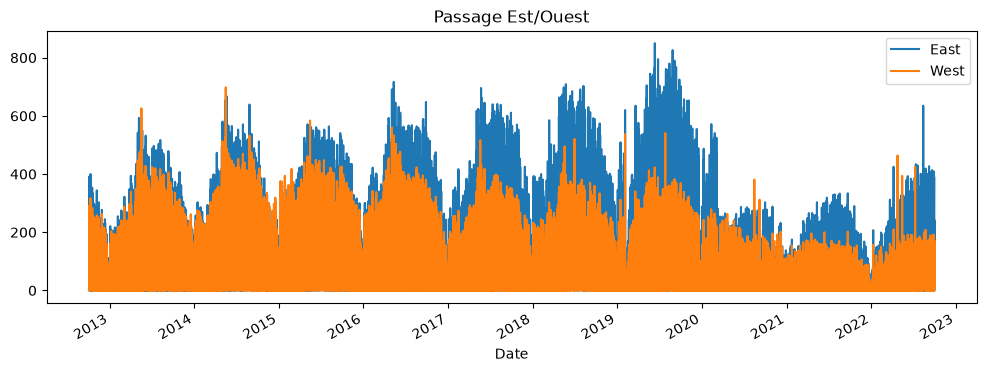

In [367]:
#A quoi ça ressemble

data[['East', 'West']].plot(figsize=(12,4),title = "Passage Est/Ouest")
plt.show()

87600
522
521.4285714285714


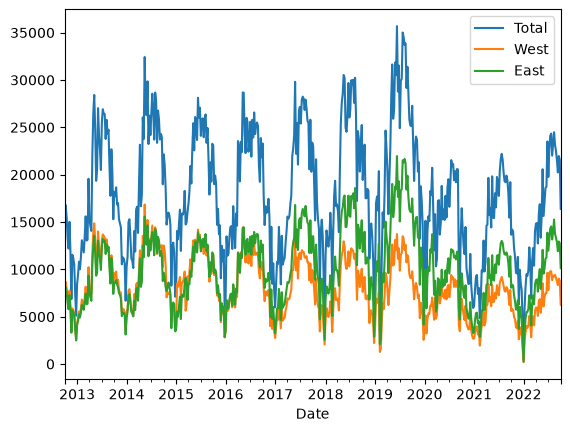

In [368]:
#Resample

data.resample("1W").sum().plot()
print(data.shape[0]) #shape[0] pour le nombre de lignes
print(data.resample("1W").sum().shape[0])
print(87600/(7*24)) #OK !

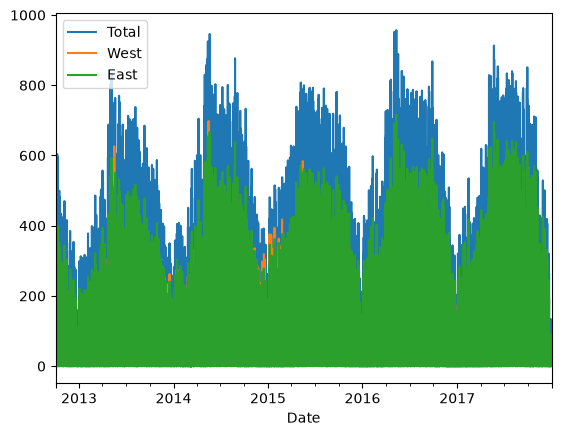

In [369]:
#Découpage temporel

data = data[data.index.year <= 2017]
#data = data[data.index <= "2017-02-12 14:32:30"]
data.plot()
plt.show()

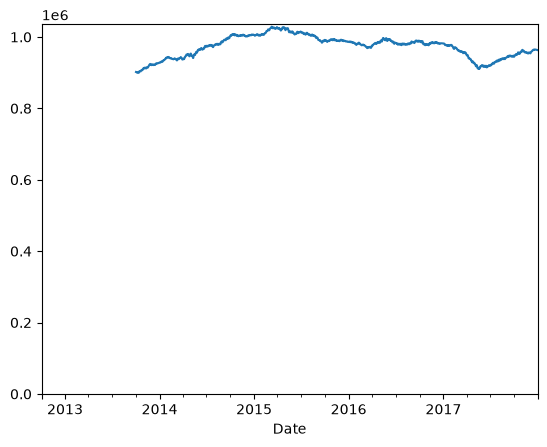

In [370]:
#Evolution annuelle

data_annuel = data["Total"].resample("1D").sum().rolling(365).sum() #resample
#sur un jour puis addition sur les 365 jours passés
im_annuel = data_annuel.plot() #affichage
im_annuel.set_ylim(bottom=0) #axe des Y commence à 0
plt.show()

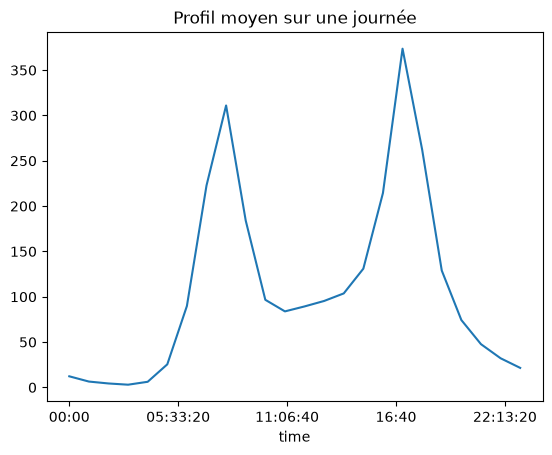

In [371]:
#Profil journalier moyen
profil_jour = data.groupby(data.index.time)["Total"].mean() #indication
profil_jour.plot(title="Profil moyen sur une journée")
plt.show()

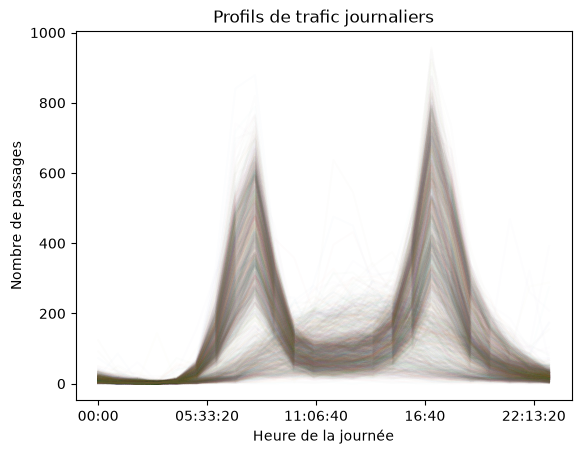

In [372]:
#Une courbe par jour

pivoted = data.pivot_table(index = data.index.time, columns = data.index.date, values = 'Total') #on
#choisit l'index voulu puis la colonne puis les valeurs
im_pivot = pivoted.plot(legend = False, alpha = 0.01) #enlever légende et mettre en transparent

im_pivot.set_title("Profils de trafic journaliers")
im_pivot.set_xlabel("Heure de la journée")
im_pivot.set_ylabel("Nombre de passages")
plt.show()


In [373]:
#Classification des jours

pca_input = pivoted.T #transposée
pca_input = pca_input.fillna(0) #remplacer valeurs manquantes par 0
display(pca_input) #afffichage


,00:00:00,01:00:00,02:00:00,03:00:00,04:00:00,05:00:00,06:00:00,07:00:00,08:00:00,09:00:00,...,14:00:00,15:00:00,16:00:00,17:00:00,18:00:00,19:00:00,20:00:00,21:00:00,22:00:00,23:00:00
2012-10-03,13.0,10.0,2.0,5.0,7.0,31.0,155.0,352.0,437.0,276.0,...,128.0,164.0,315.0,583.0,380.0,128.0,80.0,63.0,49.0,17.0
2012-10-04,18.0,3.0,9.0,3.0,8.0,26.0,142.0,319.0,418.0,241.0,...,119.0,147.0,275.0,507.0,378.0,164.0,83.0,70.0,46.0,41.0
2012-10-05,11.0,8.0,7.0,4.0,9.0,25.0,105.0,319.0,370.0,212.0,...,125.0,164.0,310.0,434.0,316.0,115.0,68.0,42.0,36.0,32.0
2012-10-06,15.0,15.0,9.0,3.0,5.0,5.0,27.0,33.0,105.0,114.0,...,203.0,211.0,183.0,180.0,96.0,78.0,43.0,33.0,34.0,34.0
2012-10-07,11.0,17.0,3.0,6.0,3.0,9.0,17.0,26.0,69.0,103.0,...,241.0,231.0,225.0,191.0,113.0,49.0,55.0,47.0,18.0,16.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017-12-27,4.0,2.0,0.0,1.0,4.0,17.0,42.0,58.0,118.0,63.0,...,45.0,73.0,133.0,111.0,62.0,34.0,27.0,21.0,10.0,7.0
2017-12-28,2.0,0.0,2.0,2.0,8.0,21.0,43.0,83.0,117.0,83.0,...,30.0,62.0,101.0,133.0,51.0,51.0,18.0,15.0,14.0,3.0
2017-12-29,11.0,2.0,2.0,2.0,5.0,15.0,35.0,56.0,70.0,39.0,...,35.0,40.0,60.0,66.0,29.0,24.0,10.0,7.0,6.0,4.0
2017-12-30,3.0,2.0,1.0,2.0,3.0,5.0,9.0,17.0,29.0,33.0,...,75.0,69.0,89.0,27.0,26.0,13.0,26.0,14.0,12.0,8.0


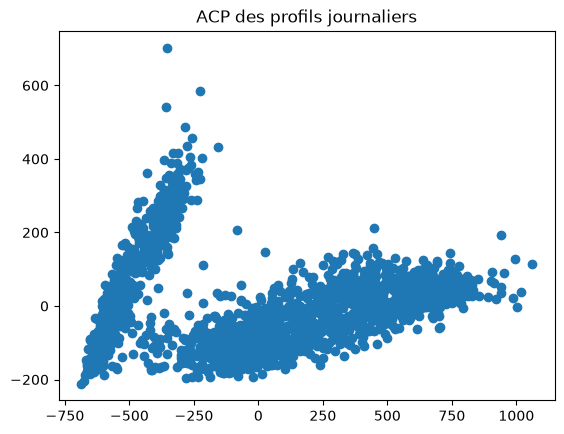

In [374]:
#ACP

from sklearn.decomposition import PCA

pca_input = PCA(n_components = 2).fit_transform(pca_input) #indication
plt.scatter(pca_input[:, 0], pca_input[:, 1]) #parce que on 
#ne peut pas plot un tableau numpy
plt.title("ACP des profils journaliers")
plt.show()

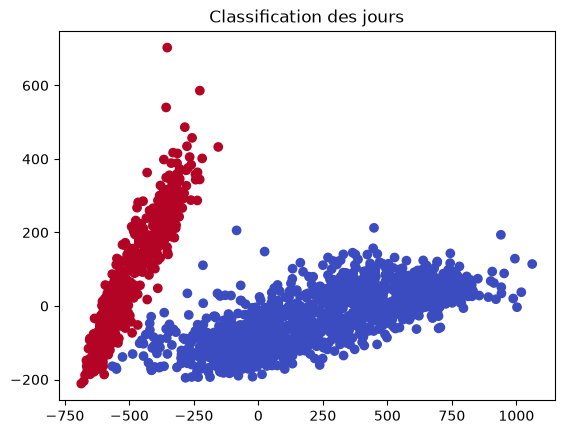

In [375]:
from sklearn.mixture import GaussianMixture

labels = GaussianMixture(n_components=2).fit_predict(pca_input)
plt.scatter(pca_input[:, 0], pca_input[:, 1], c = labels, cmap = 'coolwarm') #on
#prend tous les x puis tous les y de pca puis on attribue la couleur et on
#décide de la palette
plt.title("Classification des jours")
plt.show()

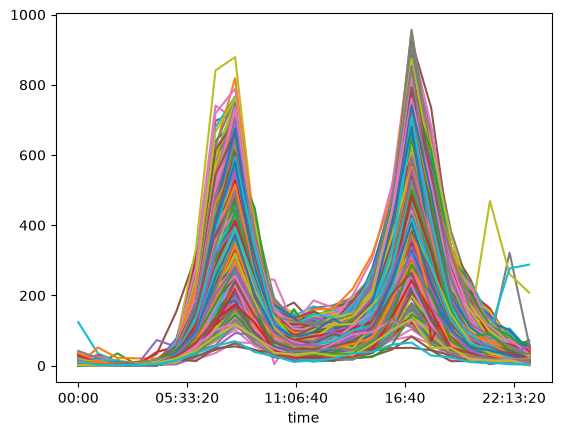

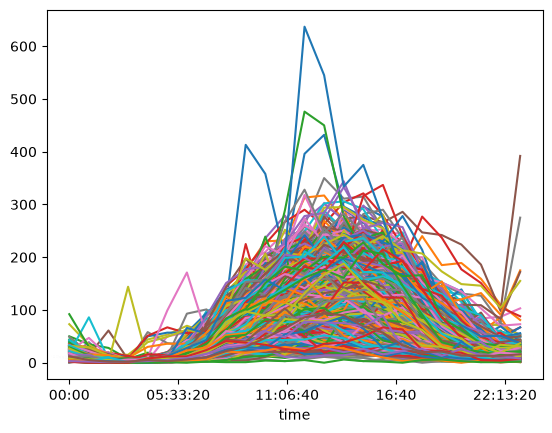

In [376]:
#Comparons chaque famille aux profils journaliers

pivoted.loc[:, labels == 0].plot(legend = None) #indication
plt.show()

pivoted.loc[:, labels == 1].plot(legend = None)
plt.show()

#selon les jours on observe un pic vers midi et sinon deux pics, 
#un à 7h et un à 17h (heures de déplacement au travail)

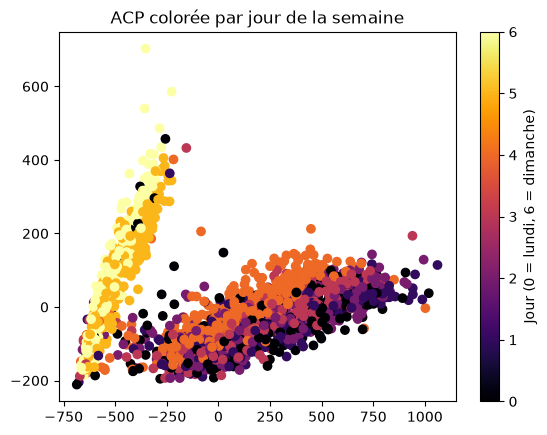

In [377]:
#Vérifions avec le jour de la semaine

jours_semaine = pd.DatetimeIndex(pivoted.columns).dayofweek

plt.scatter(pca_input[:, 0], pca_input[:, 1], c = jours_semaine, cmap = 'inferno')

plt.title("ACP colorée par jour de la semaine")
plt.colorbar(label="Jour (0 = lundi, 6 = dimanche)")
plt.show()

DatetimeIndex(['2012-11-22', '2012-11-23', '2012-12-24', '2012-12-25',
               '2012-12-31', '2013-01-01', '2013-05-27', '2013-07-04',
               '2013-09-02', '2013-11-28', '2013-11-29', '2013-12-24',
               '2013-12-25', '2014-01-01', '2014-05-26', '2014-07-04',
               '2014-09-01', '2014-11-27', '2014-11-28', '2014-12-24',
               '2014-12-25', '2014-12-26', '2015-01-01', '2015-05-25',
               '2015-07-03', '2015-09-07', '2015-11-26', '2015-11-27',
               '2015-12-24', '2015-12-25', '2015-12-31', '2016-01-01',
               '2016-05-30', '2016-07-04', '2016-09-05', '2016-11-24',
               '2016-11-25', '2016-12-26', '2016-12-30', '2017-01-02',
               '2017-02-06', '2017-05-29', '2017-07-04', '2017-09-04',
               '2017-11-23', '2017-11-24', '2017-12-25', '2017-12-26'],
              dtype='datetime64[s]', freq=None)


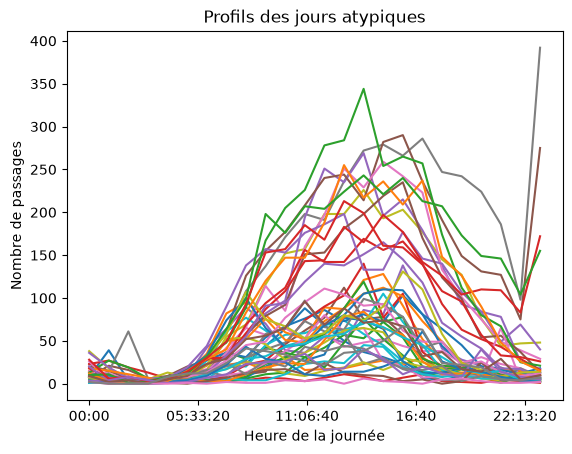

In [378]:
dates = pd.DatetimeIndex(pivoted.columns)
jours_semaine = dates.dayofweek

odd_index = (labels == 1) & (jours_semaine < 5)

odd_dates = dates[odd_index]
print(odd_dates)

pivoted[odd_dates].plot(legend=False, title="Profils des jours atypiques")

plt.xlabel("Heure de la journée")
plt.ylabel("Nombre de passages")
plt.show()